# mel_sandbox_data_5: From electrodes to regions (Data task, item 5)

The connectome only knows **regions** (Destrieux atlas), not electrodes. So we translate the electrode data
into region data. Three questions:

1. **Which region is each electrode in?** Number in `Destrieux_label` + `hemisphere` (not the label text,
   which is spelled differently across patients).
2. **What is the stimulation site?** The region(s) of the two stimulated electrodes. Here we only record
   whether the pair lies in one or two regions. How to *model* a two-region site is decided later.
3. **When does a recorded region count as responding?** A region can hold several electrodes, and they can
   disagree (some N1, some not). We need one rule for all patients. The plots below help choose it.

Exclusions are the same as in `mel_sandbox_data_3` (13 mm, depth, no label, bad, resected, SOZ, ...).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.paths import load_ccep, runs, electrodes_tsv, channels_tsv, load_lut, PROCESSED_DIR

EXCLUSION_RADIUS_MM = 13
EXCLUDE_SOZ = True      # SOZ is only annotated in some patients; see mel_sandbox_data_3, section 8
COLOR = "#3b6fb6"

cc = load_ccep()
print(len(cc), "patients")

74 patients


## 1. One table with one row per entry (recording channel x stimulation pair)

Same construction as in `mel_sandbox_data_3`, plus new columns:

- `rec_region`: region of the **recording** electrode, written as hemisphere + Destrieux number, e.g. `L_37`.
- `stim_region_a`, `stim_region_b`: regions of the two **stimulated** electrodes.

Everything is matched **by electrode name**, because `channel_names` and electrodes.tsv are not always in
the same order.

In [2]:
def norm(name):
    return str(name).strip().upper()


def region_key(hemi, label):
    # 'L_37' etc.; None if hemisphere or label is missing
    if pd.isna(hemi) or pd.isna(label):
        return None
    return f"{str(hemi).strip().upper()}_{int(label)}"


rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"])
    el["key"] = el["name"].map(norm)
    el["region"] = [region_key(h, l) for h, l in zip(el["hemisphere"], el["Destrieux_label"])]
    el_index = {k: i for i, k in enumerate(el["key"])}   # row in electrodes.tsv = row in nativeElecDistances
    el_by_key = el.set_index("key")
    D = np.asarray(p["nativeElecDistances"], dtype=float)
    D_pad = np.vstack([np.hstack([D, np.full((len(D), 1), np.nan)]), np.full((1, len(D) + 1), np.nan)])

    for r_i, r in enumerate(runs(p)):
        ch_names = [norm(c) for c in r["channel_names"]]
        n1 = np.asarray(r["n1_peak_sample"], dtype=float)           # channels x stimulation pairs
        pairs = [tuple(norm(x) for x in str(s).split("-")) for s in r["stimpair_names"]]
        currents = [np.min(np.atleast_1d(np.asarray(c, dtype=float))) * 1000 for c in r["stimpair_currents"]]

        ch_i = np.array([el_index.get(c, -1) for c in ch_names])
        a_i = np.array([el_index.get(a, -1) for a, b in pairs])
        b_i = np.array([el_index.get(b, -1) for a, b in pairs])
        dist = np.fmin(D_pad[np.ix_(ch_i, a_i)], D_pad[np.ix_(ch_i, b_i)])   # closer stimulated electrode

        ch_tsv = channels_tsv(p["id"], p["ses"], r["runName"])
        bad = set(ch_tsv.loc[ch_tsv["status"].astype(str).str.lower() == "bad", "name"].map(norm))

        info = el_by_key.reindex(ch_names)
        ch_flags = pd.DataFrame({
            "channel": ch_names,
            "rec_region": info["region"].to_numpy(),
            "missing_tsv": info["name"].isna().to_numpy(),
            "depth": (info["group"] == "depth").to_numpy(),
            "no_label": (info["hemisphere"].isna() | info["Destrieux_label"].isna()).to_numpy(),
            "label0": (info["Destrieux_label"] == 0).to_numpy(),
            "bad": np.isin(ch_names, list(bad)),
            "resected": (info["resected"] == "yes").to_numpy(),
            "soz": (info["soz"] == "yes").to_numpy(),
        })
        pair_info = pd.DataFrame({
            "pair": np.arange(len(pairs)),
            "pair_name": [f"{a}-{b}" for a, b in pairs],
            "stim_region_a": el_by_key["region"].reindex([a for a, b in pairs]).to_numpy(),
            "stim_region_b": el_by_key["region"].reindex([b for a, b in pairs]).to_numpy(),
            "current_mA": currents,
        })

        n_ch, n_pairs = n1.shape
        run_df = ch_flags.loc[np.repeat(np.arange(n_ch), n_pairs)].reset_index(drop=True)
        run_df.insert(0, "patient", p["id"])
        run_df.insert(1, "run", r_i)
        run_df["pair"] = np.tile(np.arange(n_pairs), n_ch)
        run_df["has_n1"] = ~np.isnan(n1.ravel())
        run_df["dist_mm"] = dist.ravel()
        run_df = run_df.merge(pair_info, on="pair", how="left")
        rows.append(run_df)

df = pd.concat(rows, ignore_index=True)
df["near_stim"] = df["dist_mm"] < EXCLUSION_RADIUS_MM
df["no_distance"] = df["dist_mm"].isna()      # a stimulated electrode is missing from electrodes.tsv

print(f"{len(df):,} entries, {df['has_n1'].sum():,} with an N1, {df['patient'].nunique()} patients")

577,740 entries, 40,168 with an N1, 74 patients


## 2. Apply the exclusions

All rules from `mel_sandbox_data_3`, plus one new one: entries **without a distance** (we cannot check the
13 mm rule there, so we drop them).

In [3]:
rules = ["missing_tsv", "bad", "no_label", "label0", "depth", "resected", "near_stim", "no_distance"]
if EXCLUDE_SOZ:
    rules.append("soz")

kept = df[~df[rules].any(axis=1)].copy()
print(f"Kept: {len(kept):,} of {len(df):,} entries ({100 * len(kept) / len(df):.1f}%), "
      f"{kept['has_n1'].sum():,} N1s, {kept['patient'].nunique()} patients")
print(f"Entries dropped only because of a missing distance: "
      f"{(df['no_distance'] & ~df[[r for r in rules if r != 'no_distance']].any(axis=1)).sum():,}")

Kept: 279,392 of 577,740 entries (48.4%), 22,037 N1s, 74 patients
Entries dropped only because of a missing distance: 0


## 3. Region names and the medial wall

The lookup table of the connectome (`lut_aparc-a2009s_mics.csv`) numbers the regions as
**1000 + Destrieux number** (left) and **2000 + Destrieux number** (right). We use it to give the regions
readable names.

Number 42 is the **medial wall** in this table: not real cortex, so it will probably not be a usable node of
the connectome. We check whether any kept electrodes carry it.

In [4]:
lut = load_lut()
lut_names = dict(zip(lut["mics"], lut["label"].str.replace("ctx_", "", regex=False)))


def region_name(key):
    hemi, num = key.split("_")
    return lut_names.get((1000 if hemi == "L" else 2000) + int(num), key)


kept["rec_region_name"] = kept["rec_region"].map(region_name)
print("Example:", "L_37 ->", region_name("L_37"))

medial = kept["rec_region"].str.endswith("_42")
print(f"Kept entries on the medial wall (label 42): {medial.sum():,} "
      f"in {kept.loc[medial, 'patient'].nunique()} patients")

Example: L_37 -> lh_G_temporal_inf
Kept entries on the medial wall (label 42): 2,674 in 10 patients


## 4. Stimulation sites: one region or two?

A site = one stimulation pair in one run of one patient. We count how often the two stimulated electrodes
lie in the **same** region and how often in **two different** regions. (How to model the second case is a
decision for the model part.)

In [5]:
site_cols = ["patient", "run", "pair"]
sites = kept.groupby(site_cols)[["pair_name", "stim_region_a", "stim_region_b", "current_mA"]].first()

def site_type(row):
    a, b = row["stim_region_a"], row["stim_region_b"]
    if pd.isna(a) or pd.isna(b):
        return "a stimulated electrode has no label"
    return "same region" if a == b else "two different regions"

sites["site_type"] = sites.apply(site_type, axis=1)
counts = sites["site_type"].value_counts().to_frame("sites")
counts["% of sites"] = (100 * counts["sites"] / len(sites)).round(1)
counts

,sites,% of sites
site_type,,
same region,2742,55.9
two different regions,2165,44.1


## 5. One row per (site, recorded region)

For each stimulation site and each recorded region we count:

- `n_elec`: kept electrodes of this region (for this site),
- `n_n1`: how many of them show an N1,
- `frac_n1` = `n_n1 / n_elec`.

The rule for "responding" will be a rule on these numbers.

In [6]:
reg = (kept.groupby(site_cols + ["rec_region"])
           .agg(n_elec=("has_n1", "size"), n_n1=("has_n1", "sum"))
           .reset_index())
reg["frac_n1"] = reg["n_n1"] / reg["n_elec"]
reg = reg.merge(sites[["stim_region_a", "stim_region_b", "site_type", "current_mA"]].reset_index(), on=site_cols)
reg["rec_in_stim_region"] = (reg["rec_region"] == reg["stim_region_a"]) | (reg["rec_region"] == reg["stim_region_b"])

print(f"{len(reg):,} (site, region) rows, {len(sites):,} sites")
print(f"Rows where the recorded region is also a stimulated region: {reg['rec_in_stim_region'].mean():.1%}")
reg.head()

71,478 (site, region) rows, 4,907 sites
Rows where the recorded region is also a stimulated region: 7.4%


,patient,run,pair,rec_region,n_elec,n_n1,frac_n1,stim_region_a,stim_region_b,site_type,current_mA,rec_in_stim_region
0,sub-ccepAgeUMCU01,0,0,L_10,2,0,0.0,L_19,L_19,same region,7.0,False
1,sub-ccepAgeUMCU01,0,0,L_12,2,0,0.0,L_19,L_19,same region,7.0,False
2,sub-ccepAgeUMCU01,0,0,L_14,4,0,0.0,L_19,L_19,same region,7.0,False
3,sub-ccepAgeUMCU01,0,0,L_15,4,0,0.0,L_19,L_19,same region,7.0,False
4,sub-ccepAgeUMCU01,0,0,L_16,1,0,0.0,L_19,L_19,same region,7.0,False


## 6. Plot 1: How many electrodes does a region have?

The responding rule only matters when a region has **2 or more** electrodes.

Unit: one **(patient, region)**, counted **within one patient**. Here we count the patient's electrodes that
pass the channel rules (bad, depth, label, resected, SOZ), not yet the 13 mm rule, because that one changes
from site to site.

- **Left:** all (patient, region) units together.
- **Right:** one column per patient, so we can see if some patients look very different from the others.

(patient, region) units: 1,058; with only 1 electrode: 28%; median electrodes per region: 3


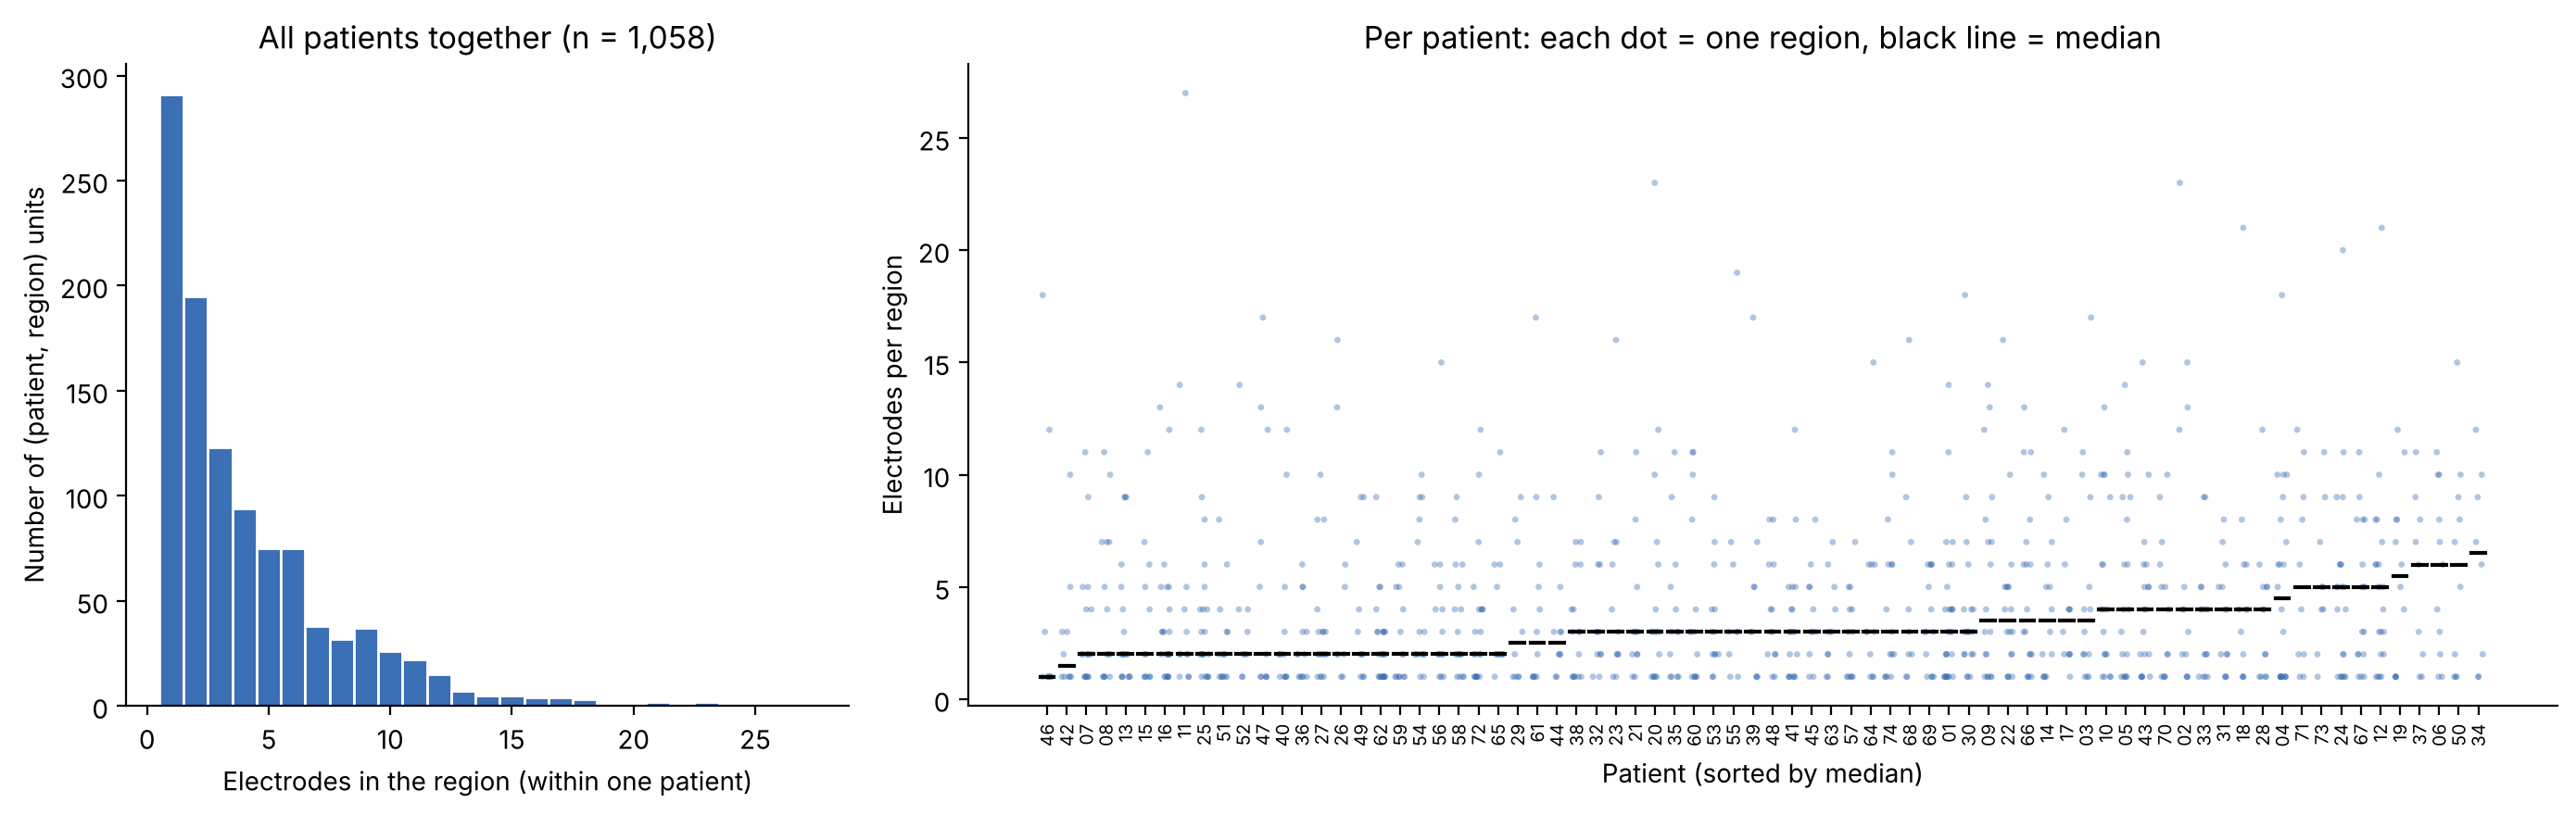

In [7]:
channel_rules = [r for r in rules if r not in ("near_stim", "no_distance")]
elec = (df[~df[channel_rules].any(axis=1)]
        .drop_duplicates(["patient", "channel"])
        .groupby(["patient", "rec_region"]).size().rename("n_elec").reset_index())

share_single = (elec["n_elec"] == 1).mean()
print(f"(patient, region) units: {len(elec):,}; with only 1 electrode: {share_single:.0%}; "
      f"median electrodes per region: {elec['n_elec'].median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})

ax = axes[0]
max_n = int(elec["n_elec"].max())
ax.hist(elec["n_elec"], bins=np.arange(0.5, max_n + 1.5, 1), color=COLOR, edgecolor="white")
ax.set_xlabel("Electrodes in the region (within one patient)")
ax.set_ylabel("Number of (patient, region) units")
ax.set_title(f"All patients together (n = {len(elec):,})")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
order = elec.groupby("patient")["n_elec"].median().sort_values().index
rng = np.random.default_rng(0)
for x, pid in enumerate(order):
    vals = elec.loc[elec["patient"] == pid, "n_elec"].to_numpy()
    ax.scatter(x + rng.uniform(-0.25, 0.25, len(vals)), vals, s=6, alpha=0.4, color=COLOR, edgecolor="none")
    ax.plot([x - 0.35, x + 0.35], [np.median(vals)] * 2, color="black", lw=1.5)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([p.replace("sub-ccepAgeUMCU", "") for p in order], rotation=90, fontsize=7)
ax.set_xlabel("Patient (sorted by median)")
ax.set_ylabel("Electrodes per region")
ax.set_title("Per patient: each dot = one region, black line = median")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 7. Plot 2 (the key plot): Do electrodes in the same region agree?

Only (site, region) rows with **2 or more** electrodes. For each we take the share of its electrodes with
an N1 (`frac_n1`, from 0 to 1).

- **Two peaks at 0 and 1** → electrodes agree; any rule gives (almost) the same answer.
- **Many values in between** → electrodes often disagree; the threshold matters.

**Right:** per patient, the share of rows where the electrodes **disagree** (0 < frac < 1). This checks
whether a few patients drive the picture.

Rows with >= 2 electrodes: 50,901 (71% of all rows)
  all electrodes without N1: 79%
  all electrodes with N1:    2%
  electrodes disagree:       20%
Among rows with at least one N1: electrodes disagree in 93%


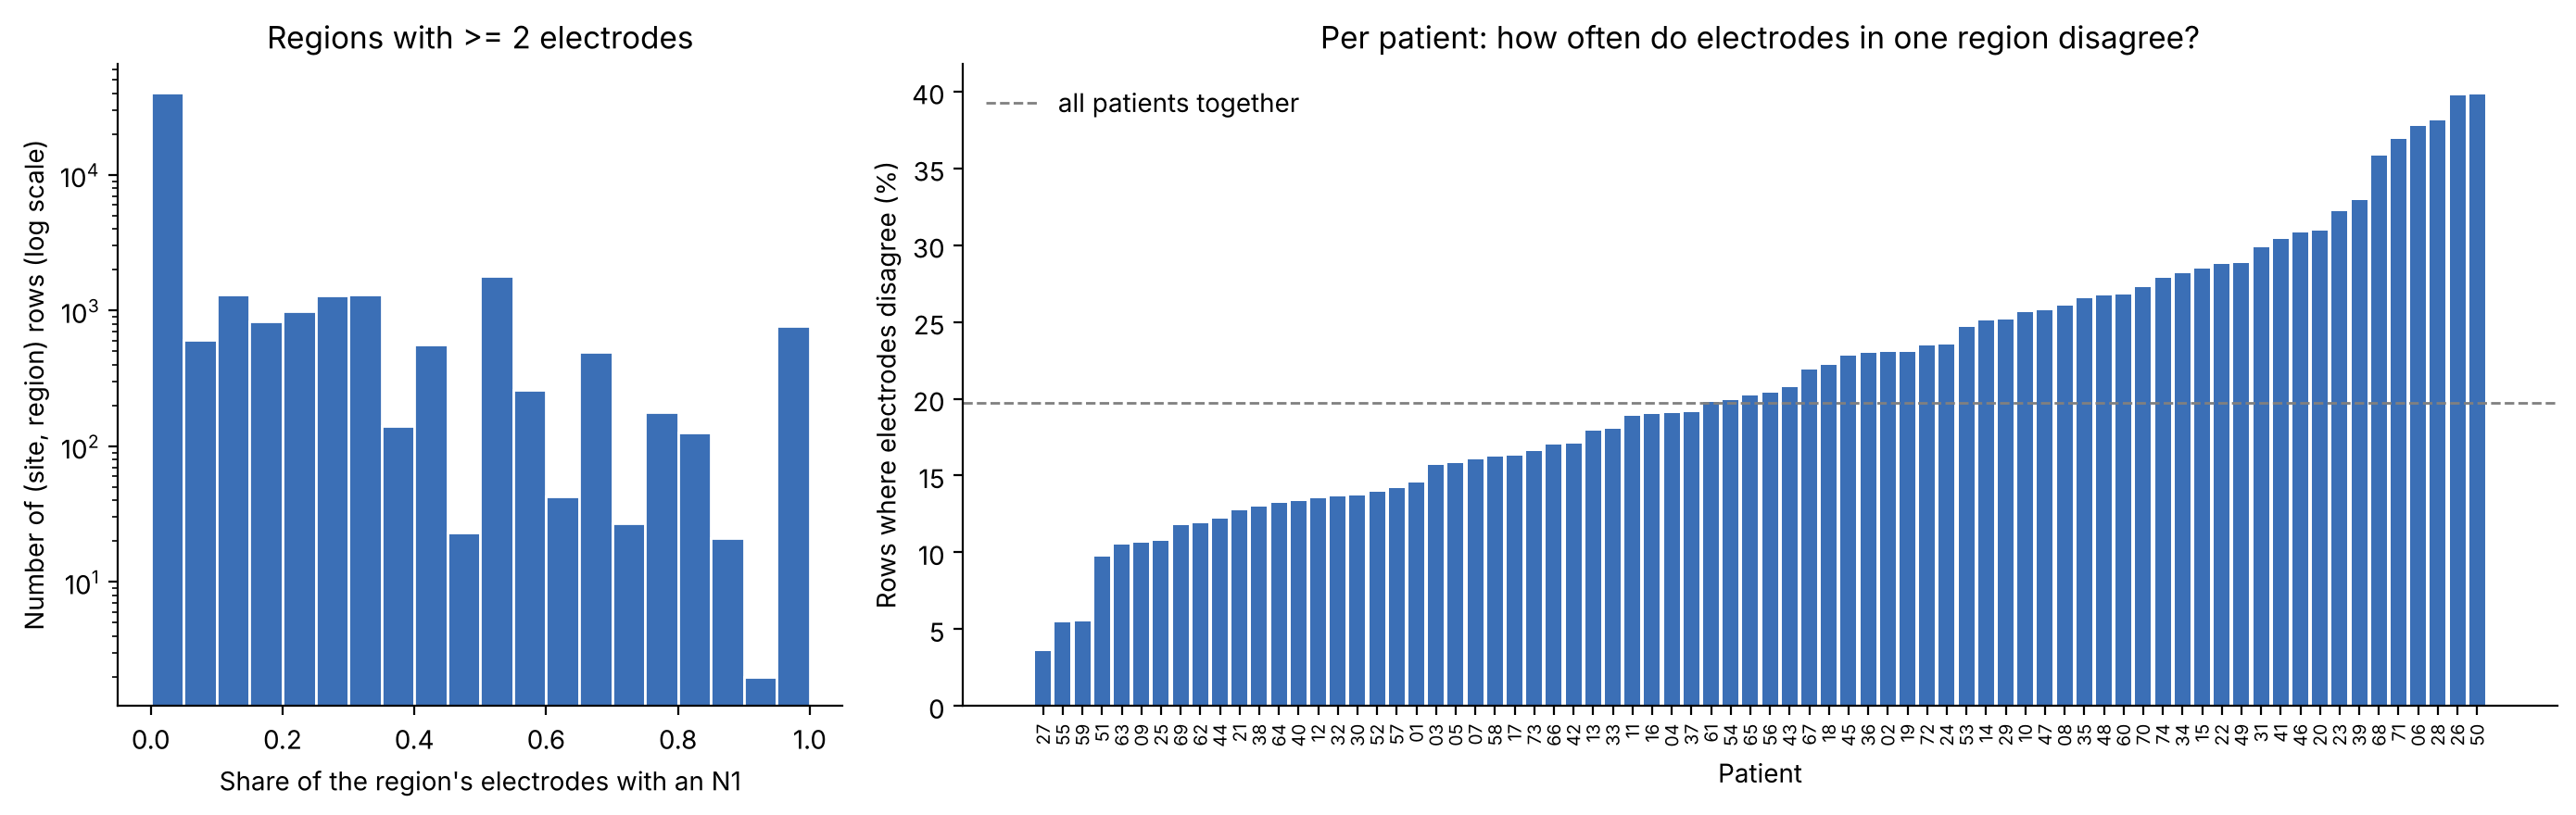

In [8]:
multi = reg[reg["n_elec"] >= 2]
disagree = (multi["frac_n1"] > 0) & (multi["frac_n1"] < 1)
print(f"Rows with >= 2 electrodes: {len(multi):,} ({len(multi) / len(reg):.0%} of all rows)")
print(f"  all electrodes without N1: {(multi['frac_n1'] == 0).mean():.0%}")
print(f"  all electrodes with N1:    {(multi['frac_n1'] == 1).mean():.0%}")
print(f"  electrodes disagree:       {disagree.mean():.0%}")
print(f"Among rows with at least one N1: electrodes disagree in "
      f"{disagree[multi['n_n1'] > 0].mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})

ax = axes[0]
ax.hist(multi["frac_n1"], bins=np.linspace(0, 1, 21), color=COLOR, edgecolor="white")
ax.set_yscale("log")
ax.set_xlabel("Share of the region's electrodes with an N1")
ax.set_ylabel("Number of (site, region) rows (log scale)")
ax.set_title("Regions with >= 2 electrodes")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
per_patient = (multi.assign(disagree=disagree)
                    .groupby("patient")["disagree"].agg(["mean", "size"])
                    .sort_values("mean"))
ax.bar(range(len(per_patient)), 100 * per_patient["mean"], color=COLOR)
ax.axhline(100 * disagree.mean(), color="grey", ls="--", lw=1, label="all patients together")
ax.set_xticks(range(len(per_patient)))
ax.set_xticklabels([p.replace("sub-ccepAgeUMCU", "") for p in per_patient.index], rotation=90, fontsize=7)
ax.set_xlabel("Patient")
ax.set_ylabel("Rows where electrodes disagree (%)")
ax.set_title("Per patient: how often do electrodes in one region disagree?")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 8. Plot 3: How much does the rule change the observed spread?

Candidate rules for "region responds":

| Rule | Region responds if ... |
|---|---|
| any | at least 1 electrode has an N1 |
| >= 25%, >= 50%, >= 75% | at least this share of its electrodes has an N1 |
| all | every electrode has an N1 |

For each site: **spread** = share of recorded regions that respond.

- **Left:** mean spread across all sites for each rule (thick line), and one thin line per patient.
- **Right:** do the rules keep the **ranking** of the sites? Spearman correlation of the site spreads
  with the spreads under the "any" rule. The later analysis compares sites with each other, so if the
  ranking stays (correlation close to 1), the choice of rule matters little for it.

,mean spread (%),Spearman r with 'any'
any,18.5,1.000
>=25%,13.0,0.902
>=50%,8.1,0.780
>=75%,4.3,0.637
all,3.9,0.608


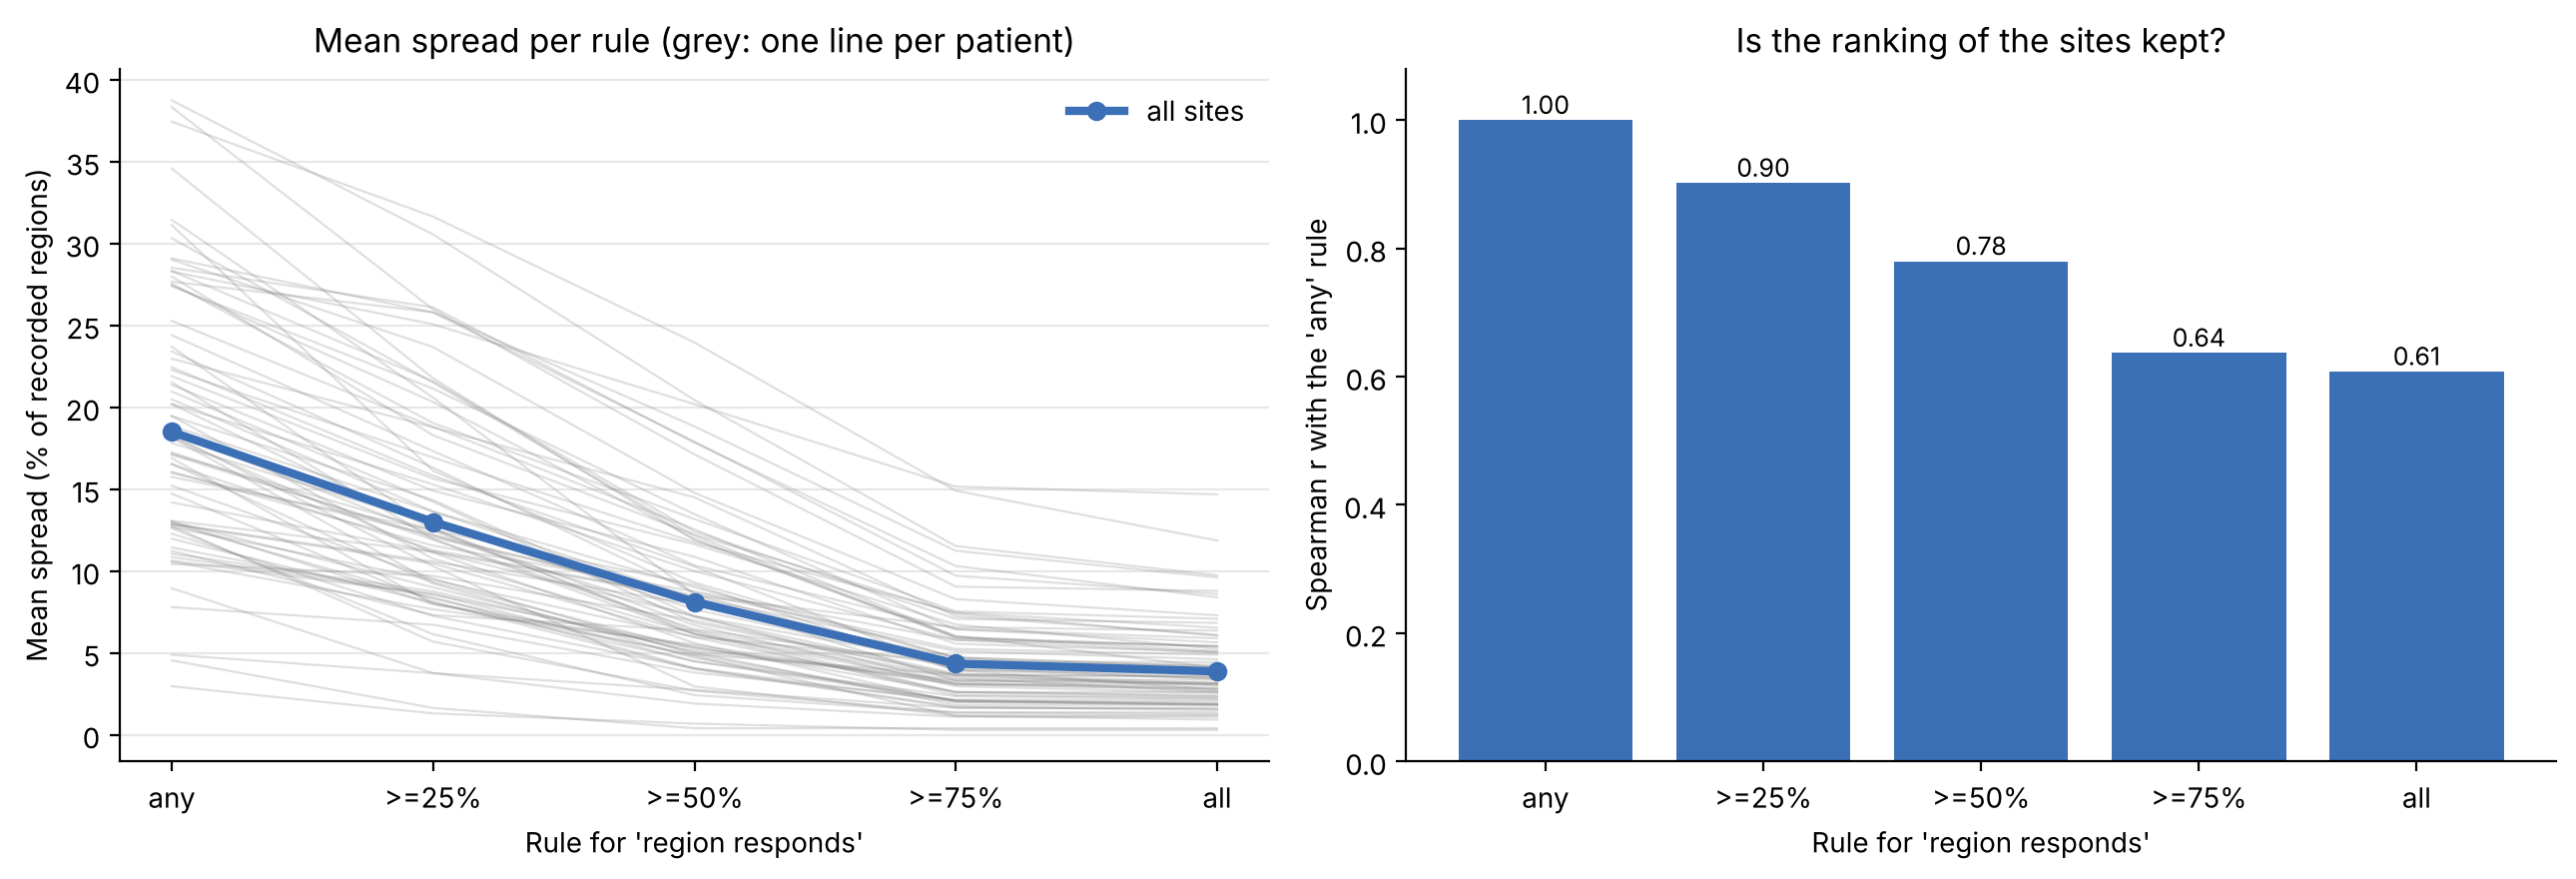

In [9]:
RULE_LIST = {
    "any": lambda r: r["n_n1"] >= 1,
    ">=25%": lambda r: r["frac_n1"] >= 0.25,
    ">=50%": lambda r: r["frac_n1"] >= 0.50,
    ">=75%": lambda r: r["frac_n1"] >= 0.75,
    "all": lambda r: r["frac_n1"] == 1,
}

spread = pd.DataFrame({
    name: reg.assign(resp=rule(reg)).groupby(site_cols)["resp"].mean()
    for name, rule in RULE_LIST.items()
})

summary = pd.DataFrame({
    "mean spread (%)": (100 * spread.mean()).round(1),
    "Spearman r with 'any'": spread.corr(method="spearman")["any"].round(3),
})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(RULE_LIST))

ax = axes[0]
per_pat = spread.groupby("patient").mean()
for _, row in per_pat.iterrows():
    ax.plot(x, 100 * row.values, color="grey", alpha=0.25, lw=0.8)
ax.plot(x, 100 * spread.mean().values, color=COLOR, lw=3, marker="o", label="all sites")
ax.set_xticks(x, RULE_LIST.keys())
ax.set_xlabel("Rule for 'region responds'")
ax.set_ylabel("Mean spread (% of recorded regions)")
ax.set_title("Mean spread per rule (grey: one line per patient)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
ax.bar(x, summary["Spearman r with 'any'"], color=COLOR)
for xi, v in zip(x, summary["Spearman r with 'any'"]):
    ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, RULE_LIST.keys())
ax.set_ylim(0, 1.08)
ax.set_xlabel("Rule for 'region responds'")
ax.set_ylabel("Spearman r with the 'any' rule")
ax.set_title("Is the ranking of the sites kept?")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 9. Save the region table

Saved for the next step (observed spread, task 6). Contains one row per (site, recorded region) with
`n_elec`, `n_n1` and `frac_n1`, so any rule can be applied later.

In [10]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out = PROCESSED_DIR / "region_responses.csv"
reg.to_csv(out, index=False)
print("Saved:", out.relative_to(ROOT), f"({len(reg):,} rows)")

Saved: data/processed/region_responses.csv (71,478 rows)


## 10. What to look for / open decisions

- **Plot 1:** if most regions have only 1 electrode, the rule barely matters, and "any" is the simplest
  choice. Do a few patients have many more electrodes per region than the rest?
- **Plot 2:** do the electrodes in one region mostly agree (peaks at 0 and 1)? If they often disagree,
  look at where the values pile up to choose a threshold.
- **Plot 3:** if the mean spread drops a lot from "any" to "all" but the Spearman r stays high, the rule
  changes the *level* of the spread but not the *ranking* of the sites. Then pick one rule for the main
  analysis and repeat with another in the robustness check (the Problem Statement asks for that anyway).
- **Recorded region = stimulated region:** a few rows record from the same region that was stimulated
  (electrodes > 13 mm away but in the same region). Decide whether they count for the spread.
- **Medial wall (label 42):** probably no usable connectome node; check when building the group connectome.
- **Two-region sites (section 4):** decide in the model part how to put the input on two regions.